# LA 05a — Full signal context, −240 to +240 minutes

**Descriptive historical event study, NOT an alpha signal.** Each event is aligned to `t=0 = completed second-touch signal candle CLOSE`. The first touch, actual entry print, and eventual exit are separate markers. **Pre-signal bars cannot know the future event's outcome or even necessarily its eventual liquidity level.**

The market path is displayed for the entire +240m after the signal **even when the simulated position has exited**. Trade-active counts are separate; lines after exit are not trade P&L. Outcomes come from the frozen A04 primary A03d fixed-stop 240m cohort. BTC and ETH are shown separately; `target/sigma60 <=1` versus `>1` context is available for subgroup comparisons. No raw trade ticks required.

In [1]:
import sys, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd().resolve()
while ROOT!=ROOT.parent and not (ROOT/'src'/'data_engineering').is_dir():
    ROOT=ROOT.parent
assert (ROOT/'src'/'data_engineering').is_dir(), 'Run Jupyter inside repo'
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.data_engineering.modeling.liquidity_absorption_stage_a import binance_root
from src.data_engineering.modeling.liquidity_absorption_stage_a05a import VERSION, Config, run
assert VERSION=='LA-A05a-0.1.0', 'git pull and restart kernel'
TEST=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests',
    '-p','test_liquidity_absorption_stage_a05a.py','-q'],cwd=str(ROOT),capture_output=True,text=True)
print(TEST.stdout[-3000:],TEST.stderr[-5000:])
assert TEST.returncode==0, 'A05a unit tests failed'
DATA=binance_root(ROOT)
OUT=ROOT/'notebooks'/'Liquidity_Absorption'/'05a'
print('A05a:',VERSION,'| Binance 1m:',DATA,'| Output:',OUT)

 ----------------------------------------------------------------------
Ran 20 tests in 1.399s

OK

A05a: LA-A05a-0.1.0 | Binance 1m: D:\MarketData\Binance | Output: D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\05a


In [2]:
decision=run(ROOT,DATA,OUT,Config())
print('Completed descriptive signal context study:')
display(decision)
assert decision['signals']==452 and decision['minute_rows']==452*481
assert decision['missing_bar_rows']>=0

Completed descriptive signal context study:


{'version': 'LA-A05a-0.1.0',
 'parent': 'LA-A04-0.1.1',
 'status': 'EXPLORATORY_RETROSPECTIVE_CONTEXT_NOT_PREDICTIVE',
 'config': {'before_min': 240,
  'after_min': 240,
  'trailing_minutes': 60,
  'flow_window_minutes': 15,
  'rv_windows': (15, 60),
  'cohort_entry_kind': 'TAKER_FIRST_POST_SIGNAL',
  'cohort_mode': 'VD18_VOL_FIXED',
  'cohort_hold_min': 240,
  'target_sigma_ratio_split': 1.0,
  'source_A04_version': 'LA-A04-0.1.1'},
 'signals': 452,
 'minute_rows': 217412,
 'phase_rows': 2712,
 'per_event_expected_rows': 481,
 'complete_pre240': 452,
 'complete_post240': 452,
 'missing_bar_rows': 0,
 'outcomes': {'TARGET': 119,
  'STOP': 202,
  'TIMEOUT': 93,
  'NO_STRUCTURAL_TARGET': 37,
  'CENSORED_TAPE_END': 1},
 'anchor': 't=0 is completed A02 second-touch signal candle close; actual entry is separate',
 'post_exit': 'market trajectory remains displayed even once position has exited; not account P&L',
 'level_reference': 'the eventually identified level applied retrospectively; pr

## Data integrity and original outcome groups

Keep all 452 candidate IDs and separate target, stop, timeout, targetless, and censored. `05a_coverage.csv` shows full 240m pre/post candle availability. Missing minutes are not imputed; rolling features require consecutive bars.

In [3]:
qc=pd.read_csv(OUT/'05a_coverage.csv')
events=pd.read_csv(OUT/'05a_cohort_metadata.csv')
curves=pd.read_csv(OUT/'05a_median_context_curves.csv')
landmarks=pd.read_csv(OUT/'05a_context_checkpoints.csv')
phases=pd.read_csv(OUT/'05a_phase_panel.csv')
phase_summary=pd.read_csv(OUT/'05a_phase_summary.csv')
print('Outcome counts by symbol:')
display(events.groupby(['symbol','eventual_outcome']).size().rename('events').reset_index())
print('Market data completeness per symbol:')
display(qc.groupby('symbol')[['complete_pre_240','complete_post_240']].agg(['sum','count']))
print('Fixed clock checkpoints:')
display(landmarks.query('feasibility_band=="ALL" and relative_min in [-240,-60,-15,0,15,60,240]')[[
    'symbol','eventual_outcome','relative_min','n_candidates','n_price_present','n_trade_active',
    'median_signed_close_from_signal_bp','median_flow_alignment_15m','median_rv_15m_bp']].round(3))

Outcome counts by symbol:


,symbol,eventual_outcome,events
0,BTCUSDT,CENSORED_TAPE_END,1
1,BTCUSDT,NO_STRUCTURAL_TARGET,16
2,BTCUSDT,STOP,96
3,BTCUSDT,TARGET,50
4,BTCUSDT,TIMEOUT,49
5,ETHUSDT,NO_STRUCTURAL_TARGET,21
6,ETHUSDT,STOP,106
7,ETHUSDT,TARGET,69
8,ETHUSDT,TIMEOUT,44


Market data completeness per symbol:


complete_pre_240       complete_post_240      
                     sum count               sum count
symbol                                                
BTCUSDT              212   212               212   212
ETHUSDT              240   240               240   240

Fixed clock checkpoints:


,symbol,eventual_outcome,relative_min,n_candidates,n_price_present,n_trade_active,median_signed_close_from_signal_bp,median_flow_alignment_15m,median_rv_15m_bp
0,ALL,STOP,-240,202,202,0,20.818,0.011,15.797
2,ALL,STOP,-60,202,202,0,11.755,-0.043,17.604
4,ALL,STOP,-15,202,202,0,6.550,-0.018,14.993
7,ALL,STOP,0,202,202,1,0.000,-0.071,15.530
10,ALL,STOP,15,202,202,165,-4.130,-0.042,16.894
...,...,...,...,...,...,...,...,...,...
274,ETHUSDT,TIMEOUT,-15,44,44,0,4.765,-0.094,17.931
277,ETHUSDT,TIMEOUT,0,44,44,0,0.000,-0.062,17.886
280,ETHUSDT,TIMEOUT,15,44,44,44,6.193,0.053,16.249
282,ETHUSDT,TIMEOUT,60,44,44,44,12.409,0.098,15.448


## Formation, approach, and post-signal phases

These **fixed phase windows** summarize what happened, not which strategy to trade. Before the signal, price relative to the *eventually identified* liquidity level is a retrospective visualization. Do not use the later label, target, stop, or level before it was actually known.

In [4]:
display(phase_summary.query('feasibility_band=="ALL"')[[
  'symbol','eventual_outcome','phase','n_events','n_complete',
  'median_signed_price_change_bp','median_aligned_flow_fraction',
  'median_median_quote_vs_prior60','median_median_rv_15m_bp',
  'median_zone_overlap_fraction']].round(3))

,symbol,eventual_outcome,phase,n_events,n_complete,median_signed_price_change_bp,median_aligned_flow_fraction,median_median_quote_vs_prior60,median_median_rv_15m_bp,median_zone_overlap_fraction
0,BTCUSDT,CENSORED_TAPE_END,approach_-60_-16,1,1,19.662,0.153,0.444,10.584,0.444
1,BTCUSDT,CENSORED_TAPE_END,context_-240_-61,1,1,-90.837,-0.048,0.718,14.221,0.022
2,BTCUSDT,CENSORED_TAPE_END,early_+16_+60,1,1,0.789,0.140,0.553,8.839,0.000
3,BTCUSDT,CENSORED_TAPE_END,formation_-15_0,1,1,-5.035,-0.043,0.288,8.590,0.125
4,BTCUSDT,CENSORED_TAPE_END,immediate_+1_+15,1,1,14.161,0.164,0.723,9.663,0.000
5,BTCUSDT,CENSORED_TAPE_END,late_+61_+240,1,1,-27.269,-0.030,0.775,9.987,0.167
12,BTCUSDT,NO_STRUCTURAL_TARGET,approach_-60_-16,16,16,10.431,0.052,0.654,15.340,0.111
13,BTCUSDT,NO_STRUCTURAL_TARGET,context_-240_-61,16,16,16.778,0.026,0.592,20.394,0.097
14,BTCUSDT,NO_STRUCTURAL_TARGET,early_+16_+60,16,16,1.119,0.062,0.747,15.103,0.144
15,BTCUSDT,NO_STRUCTURAL_TARGET,formation_-15_0,16,16,-5.887,-0.101,0.616,15.070,0.406


## Visual inspection of the entire market event window

All charts use **−240 ... +240 minutes** from signal close. An exited trade remains in market-path charts, so do not interpret the right-hand side as live P&L or a surviving-trade trajectory. Heatmaps and deterministic earliest-complete event examples help expose heterogeneity hidden by medians.

05a_price_paths.png


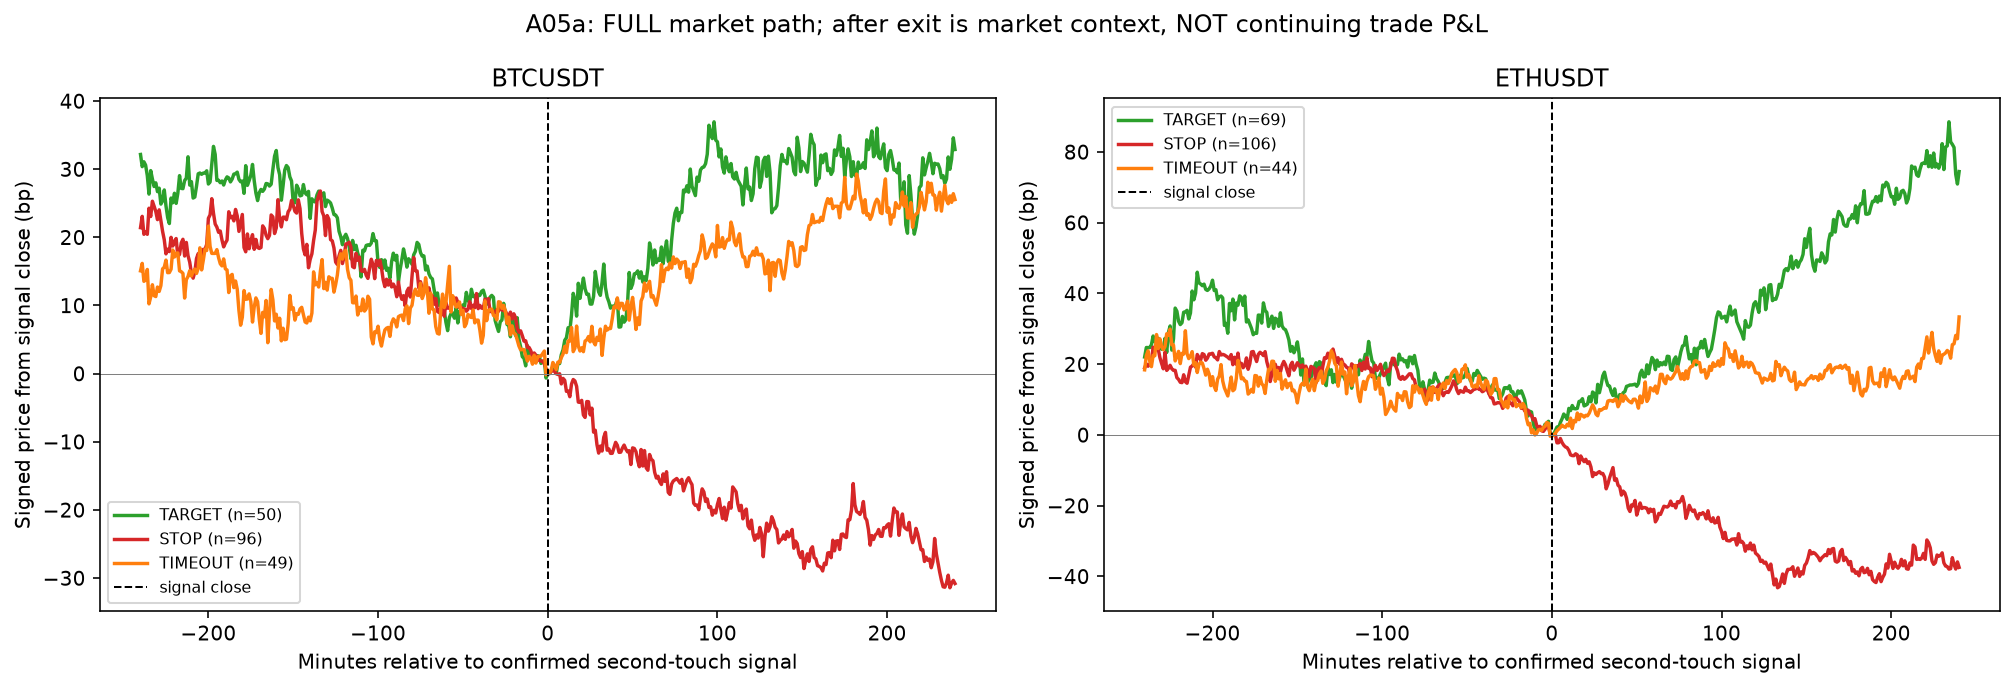

05a_level_context.png


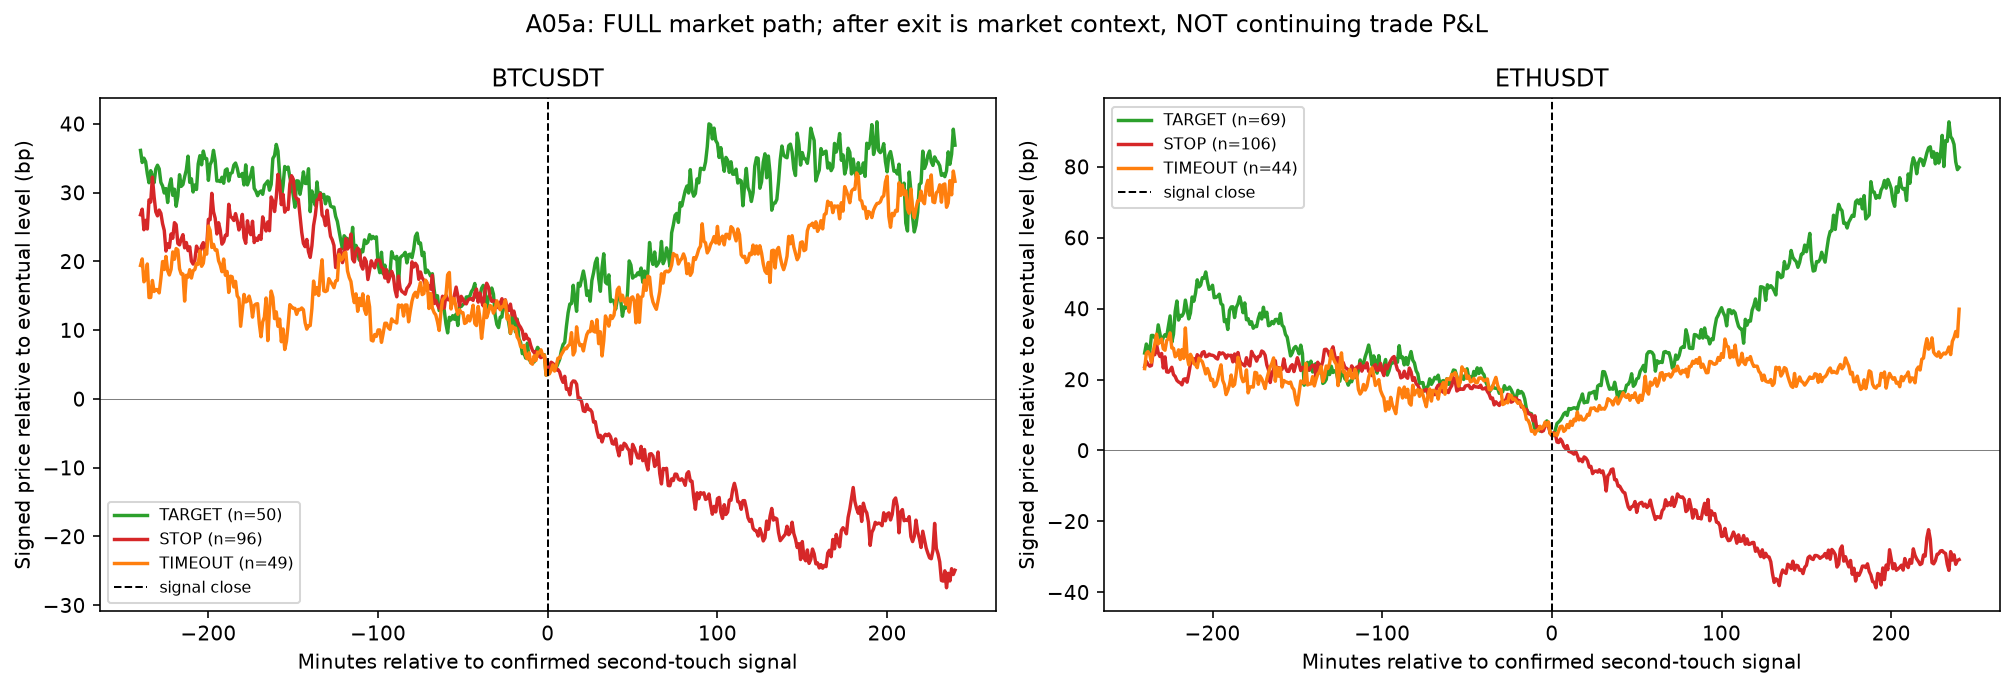

05a_rv_context.png


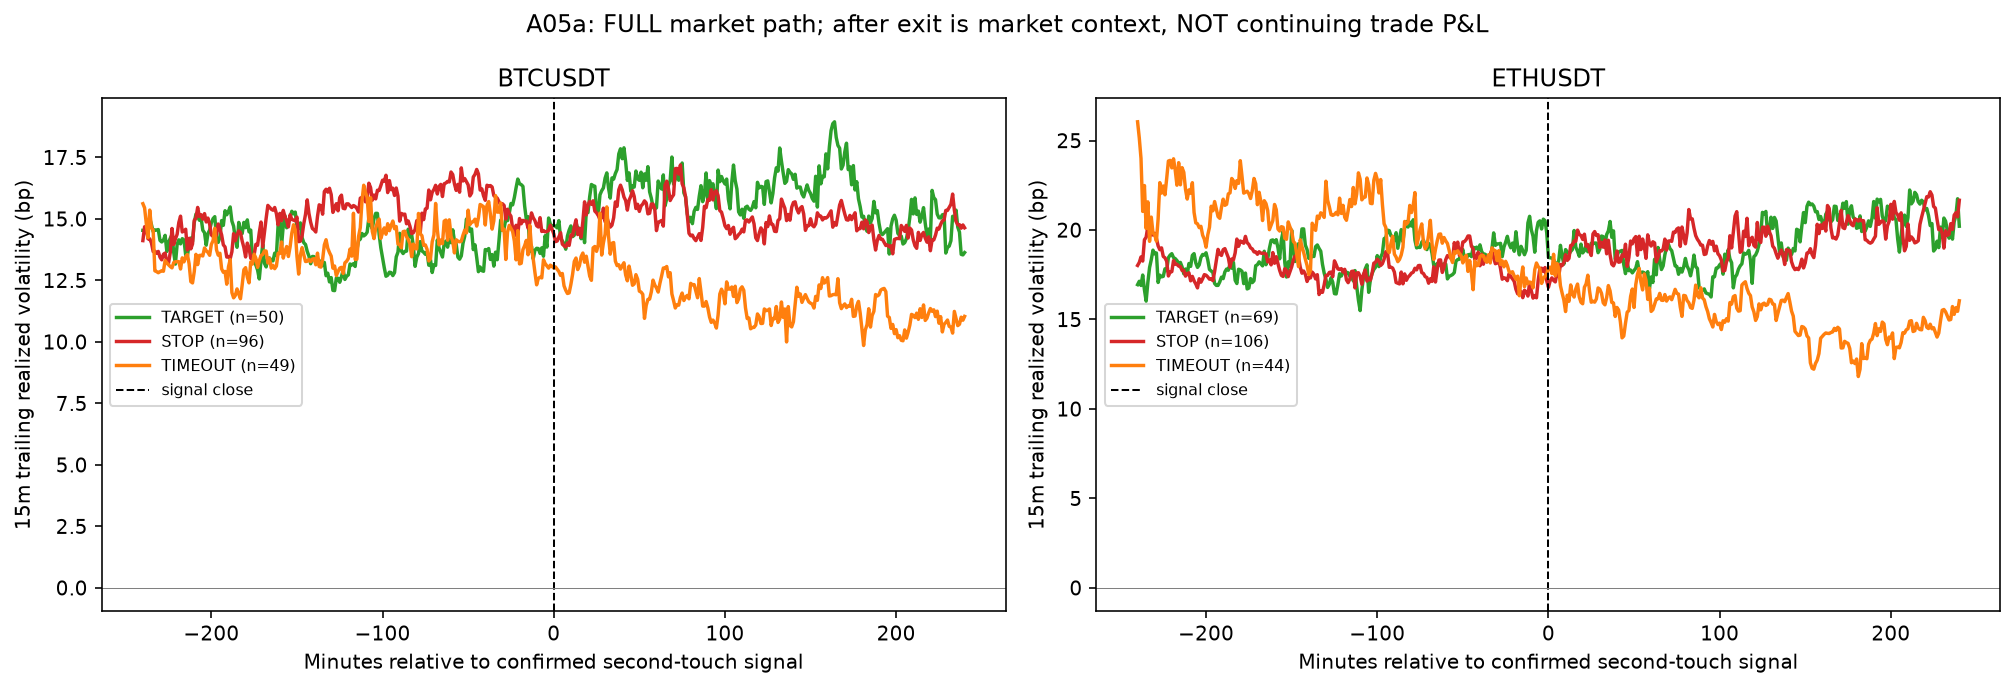

05a_activity_context.png


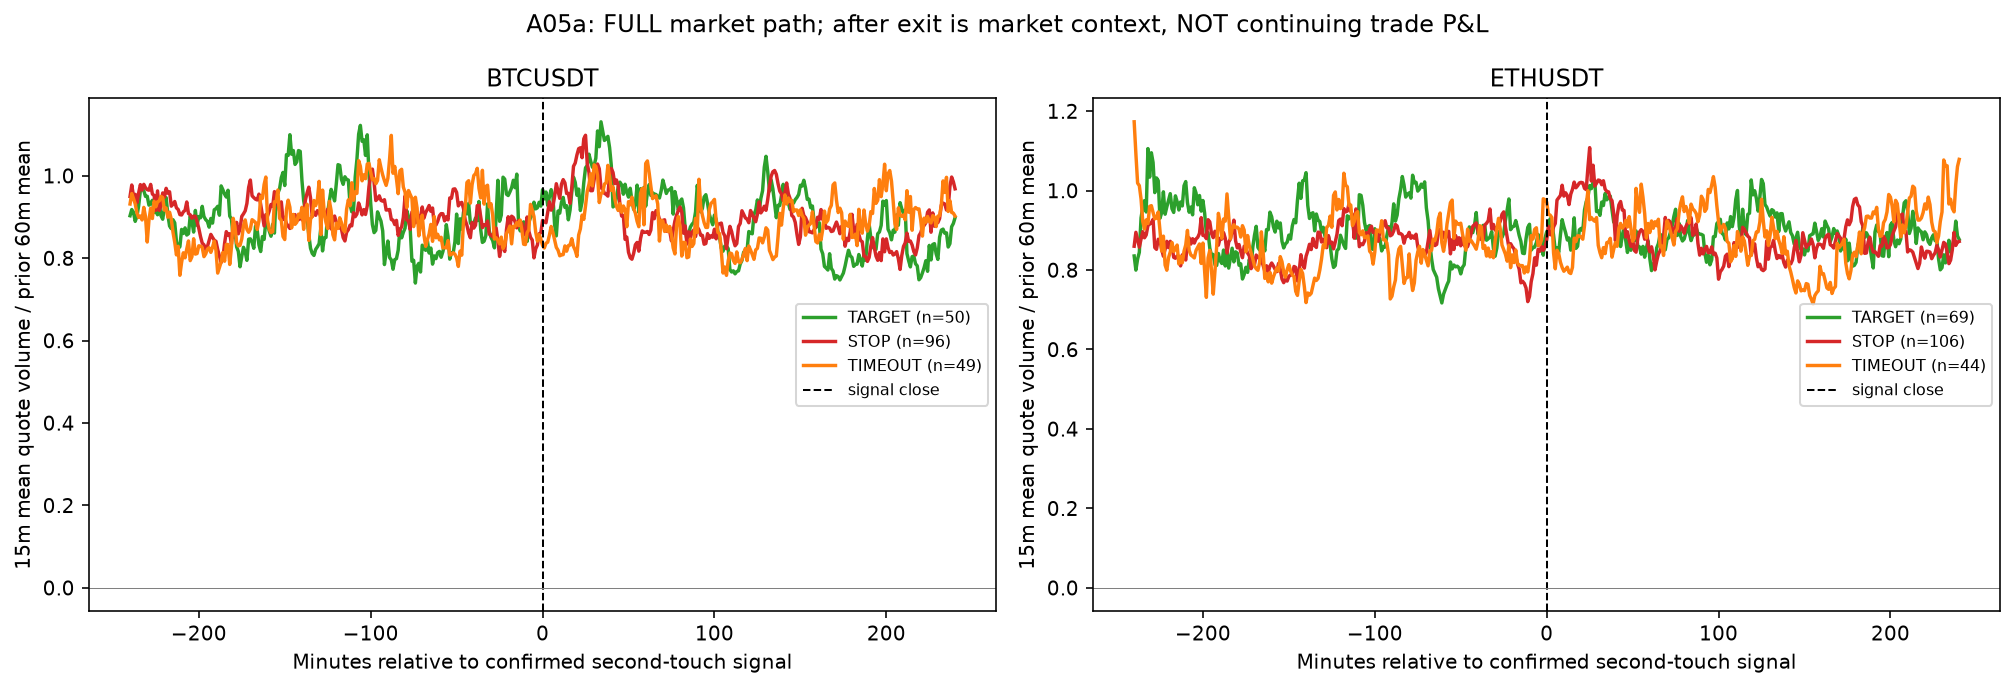

05a_flow_context.png


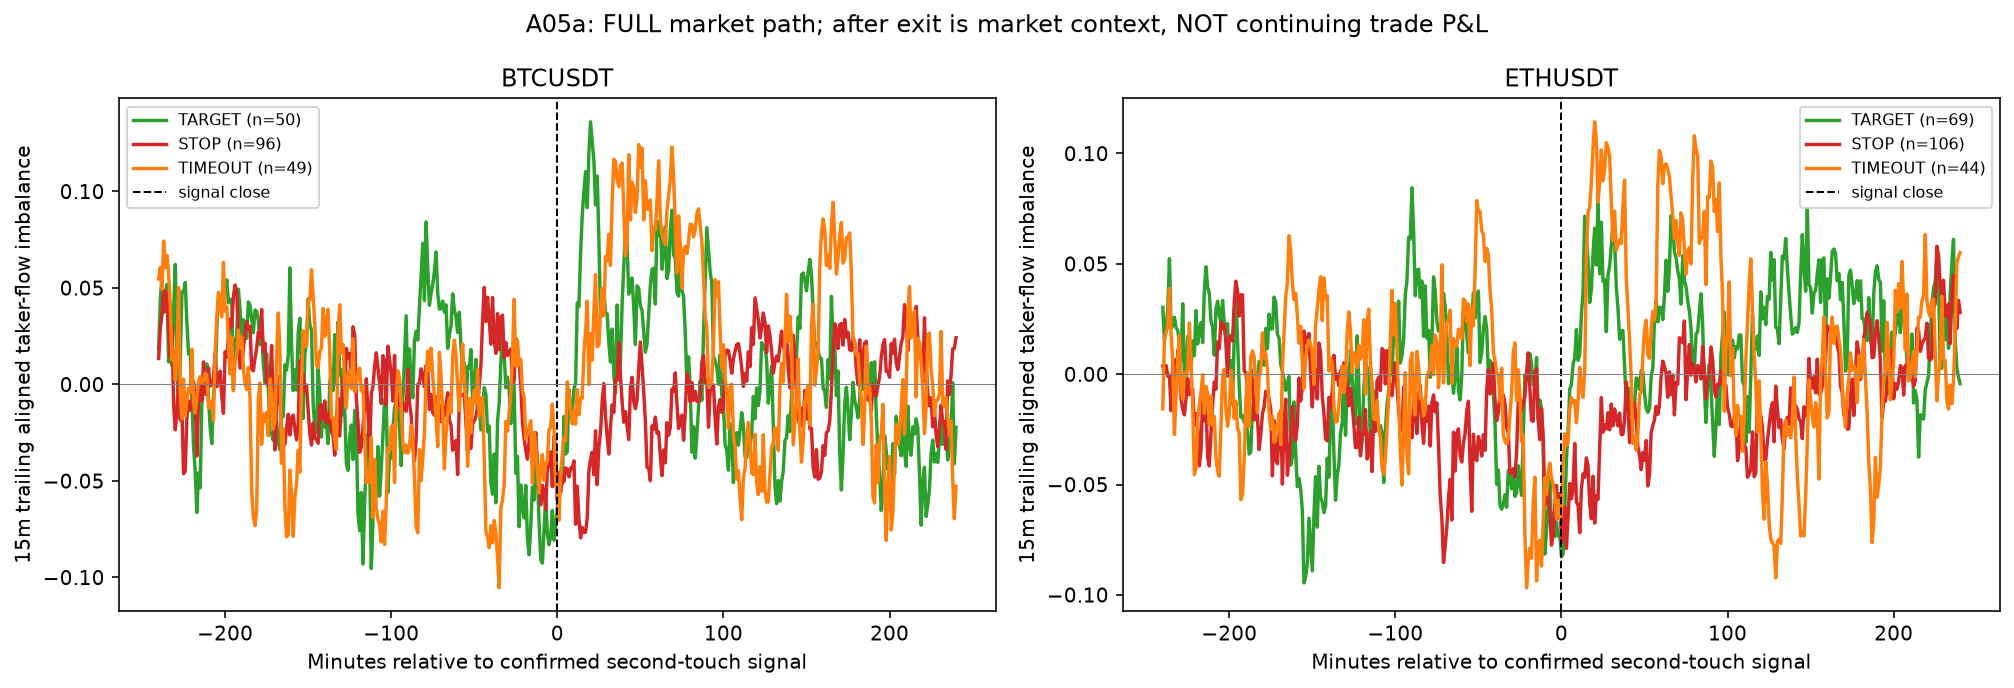

05a_BTCUSDT_event_heatmap.png


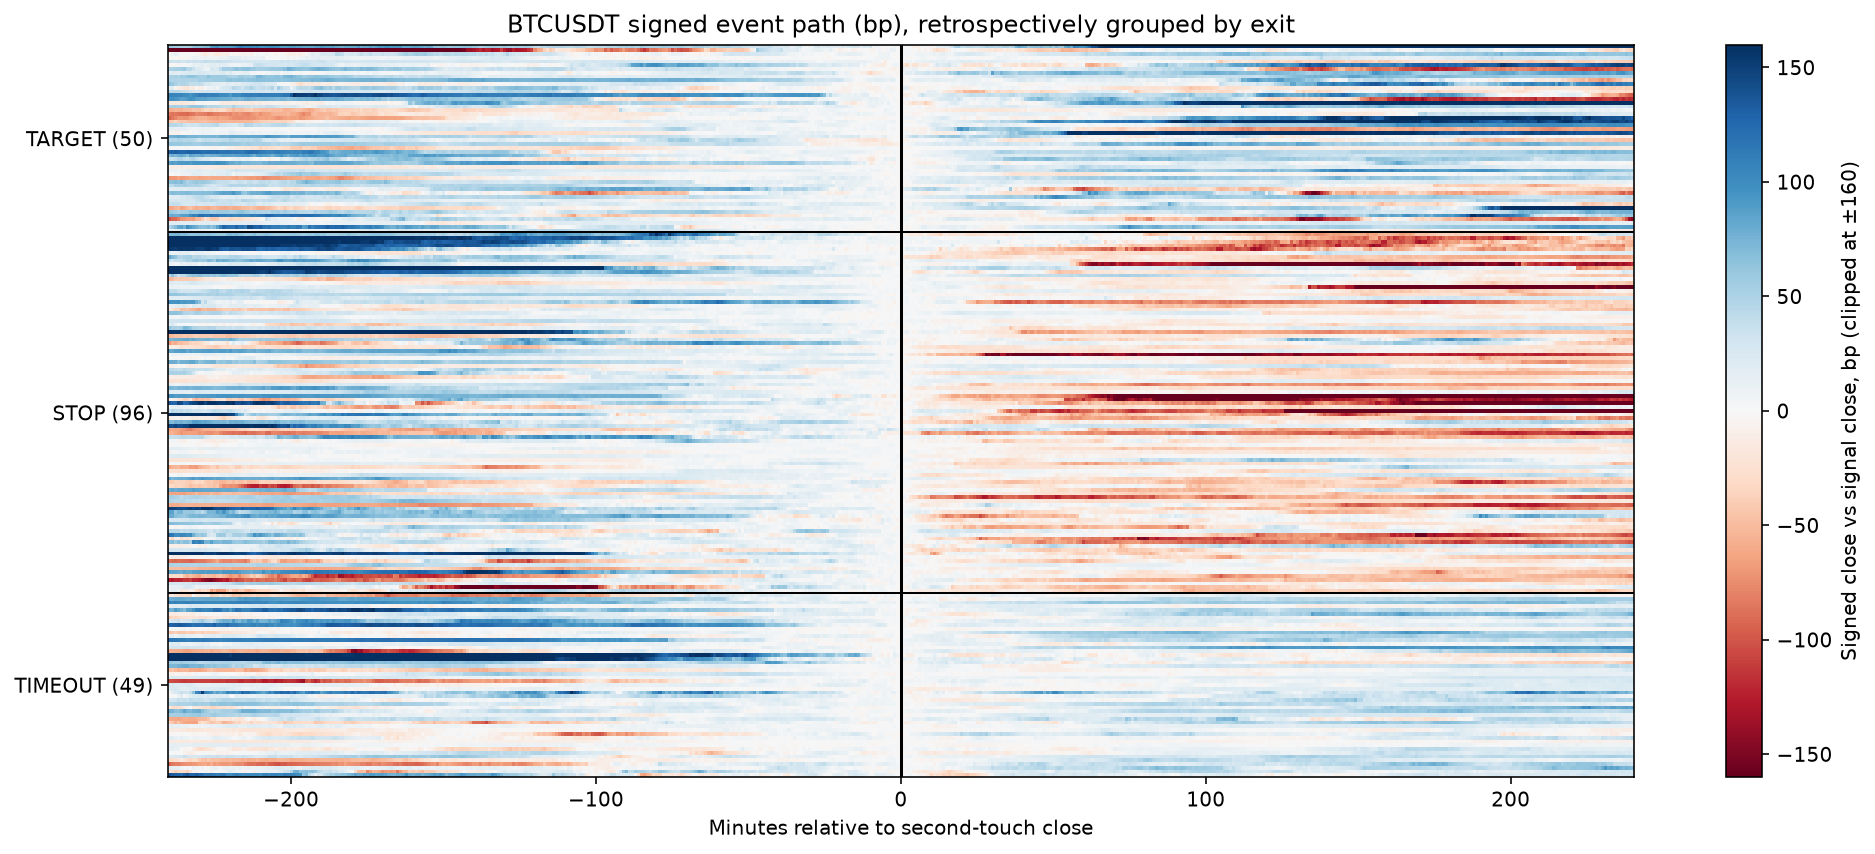

05a_ETHUSDT_event_heatmap.png


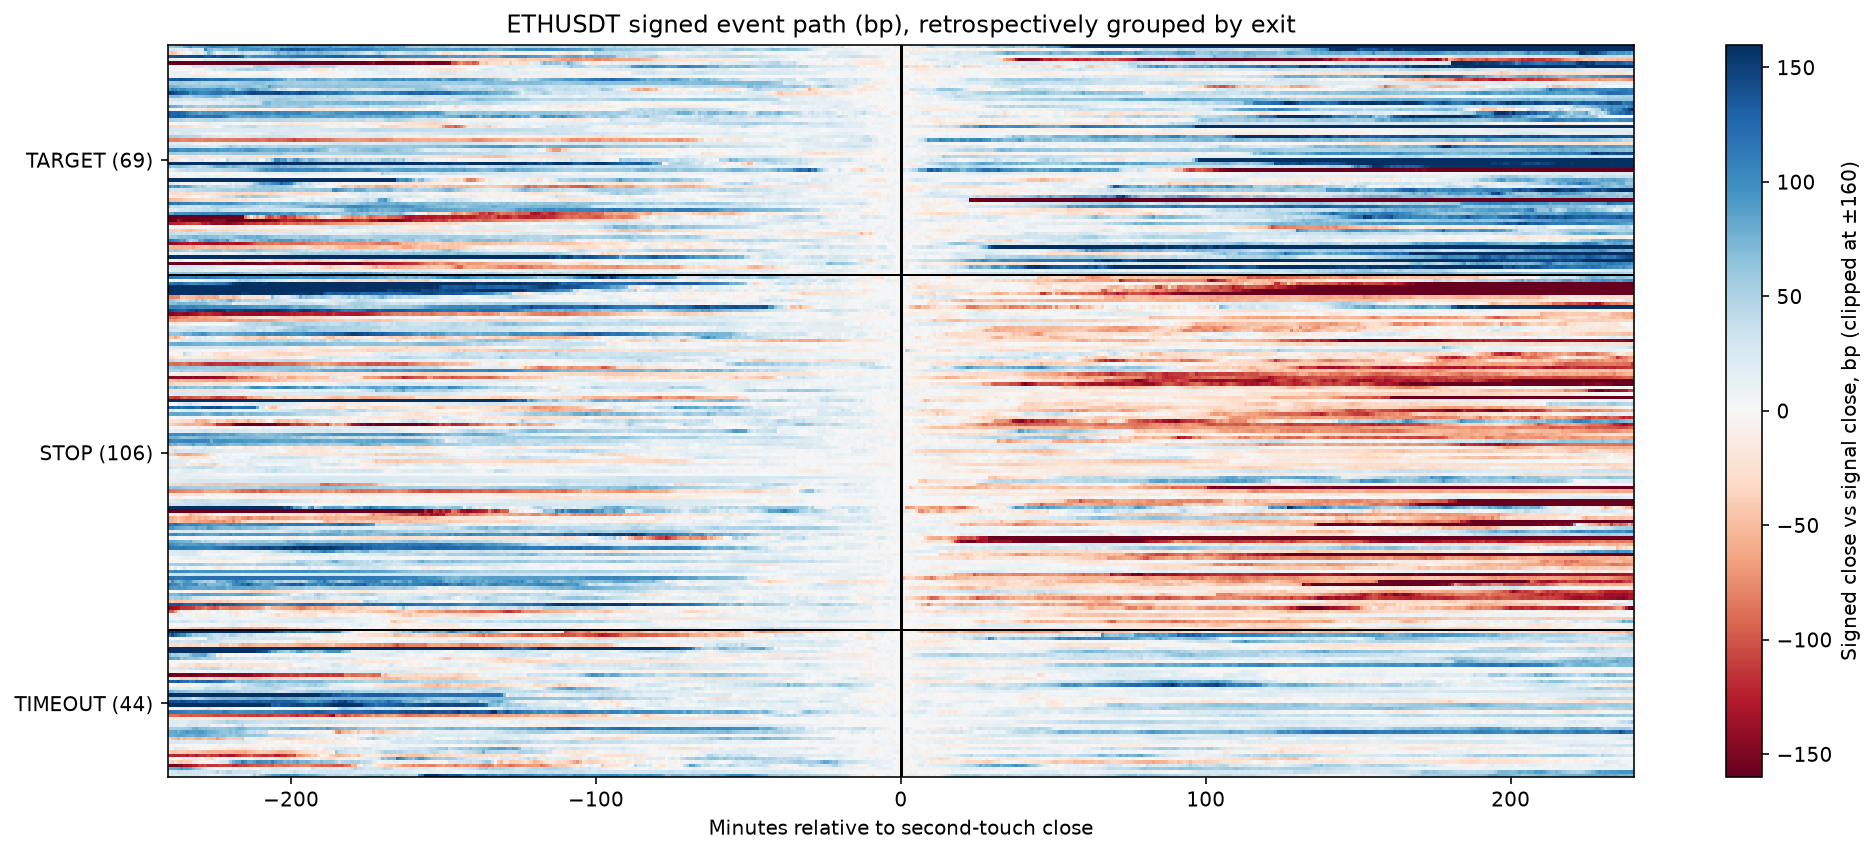

05a_example_event_timelines.png


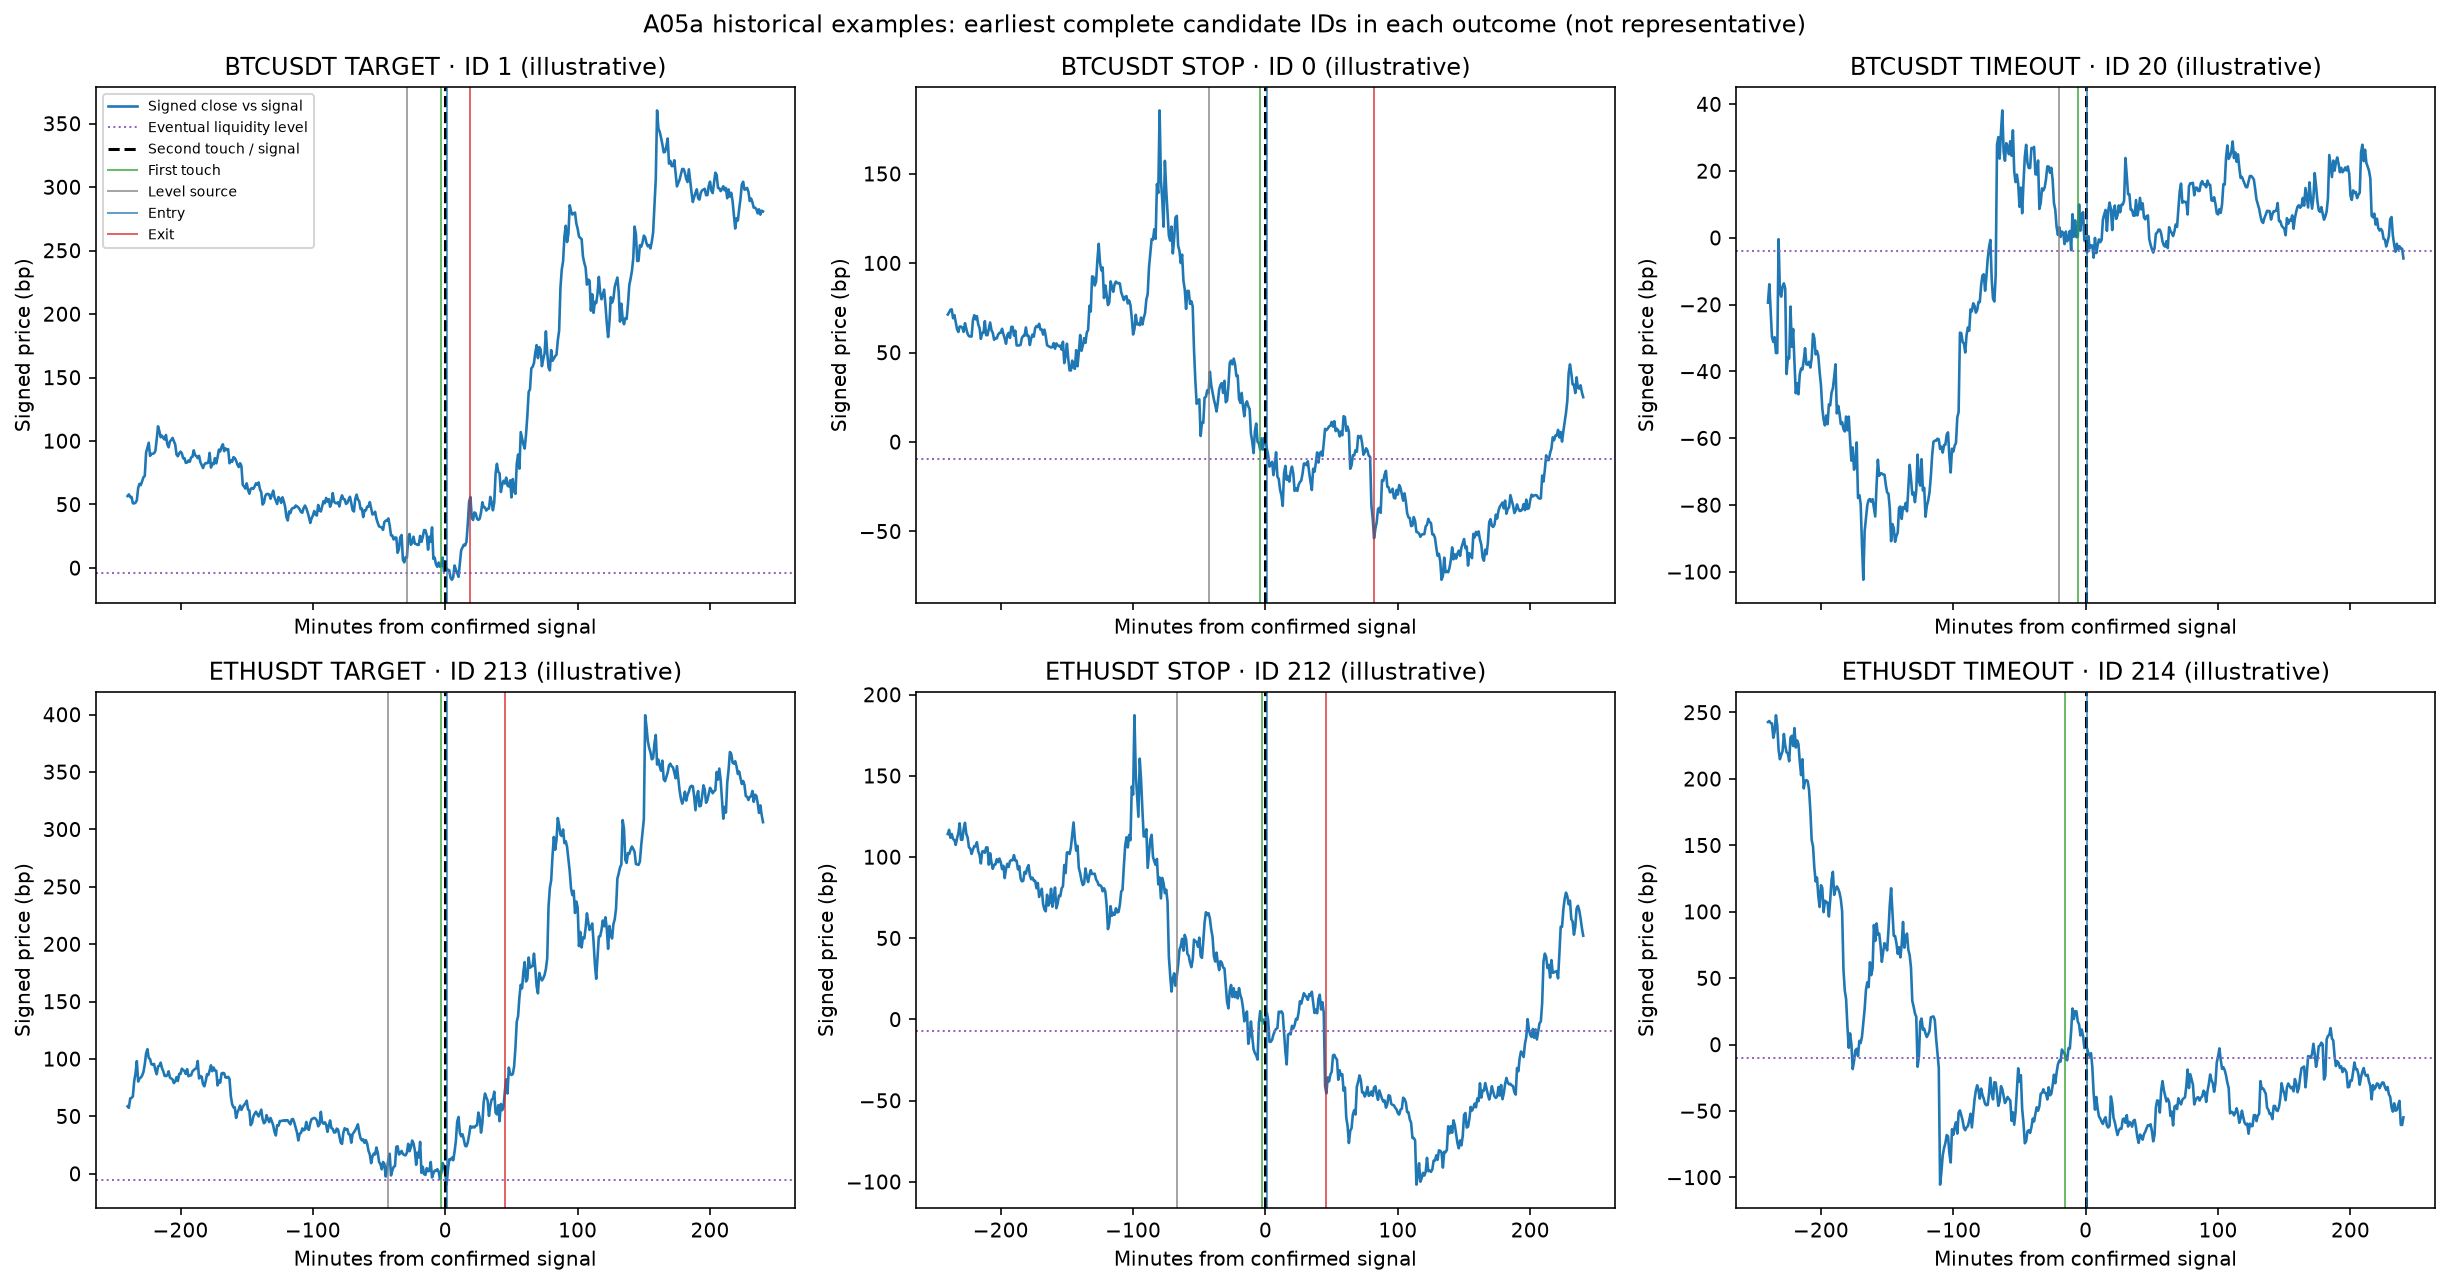

In [5]:
for pic in (
    '05a_price_paths.png', '05a_level_context.png', '05a_rv_context.png',
    '05a_activity_context.png', '05a_flow_context.png',
    '05a_BTCUSDT_event_heatmap.png', '05a_ETHUSDT_event_heatmap.png',
    '05a_example_event_timelines.png'):
    print(pic)
    display(Image(filename=str(OUT/pic)))

## Decision gate

1. Do not mistake a retrospectively chosen liquidity level for a level already identifiable at −240m; first-touch and level-source timestamps matter.
2. Do not use post-exit price changes for trade P&L or exposure.
3. Correlation of pre-signal pattern with later TARGET versus STOP does not identify passive absorption or imply profitability.
4. Geometry matters: keep the A03d target-to-VD18-sigma context as a stratification, **not** as a pre-formation feature.
5. If interesting pre-signal structures recur, freeze candidate features at t=0 and evaluate later on untouched data, grouped by asset, level family, and day.

**Next:** commit the executed notebook and `05a/` results to GitHub main for review. No earlier simulator, model, or data collector is modified.